# Notebook 02: Sparse Representations to Static Embeddings (Word2Vec)

Welcome to the second notebook in the **Embeddings from Scratch** series!

In Notebook 01, we established how vector geometry and similarity metrics work. Now, the big question is:
> **How do we convert raw words into dense, semantically meaningful vectors in the first place?**

### Learning Objectives:
1. Understand why traditional **Sparse Representations** (One-Hot, Bag-of-Words, TF-IDF) fail to capture semantics.
2. Grasp the **Distributional Hypothesis** (*"You shall know a word by the company it keeps"*).
3. Contrast the two Word2Vec architectures: **CBOW** vs. **Skip-Gram**.
4. Understand how **Negative Sampling** makes training feasible for large vocabularies.
5. Build and train a **Skip-Gram model from scratch** on a toy corpus.
6. Explore vector arithmetic (e.g., King - Man + Woman = Queen) and analyze the **polysemy limitation** of static embeddings.


---
## 1. Environment Setup
Run this on your server. If running in Google Colab, PyTorch and NumPy are pre-installed.


In [1]:
# Setup and imports
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Set random seed
torch.manual_seed(42)
np.random.seed(42)
print(f"PyTorch version: {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


PyTorch version: 2.11.0+cpu, CUDA available: False


---
## 2. Why Sparse Representations Fail

Before Word2Vec (Mikolov et al., 2013), text was represented using **sparse vectors**:
* **One-Hot Encoding**: A vocabulary of size $|V|$ represents each word as a vector with a single `1` and $|V|-1$ zeros.
* **Bag of Words (BoW)**: Counts occurrences of each word in a document.
* **TF-IDF**: Weights word counts by their inverse document frequency.

### The Fundamental Flaw of One-Hot Vectors:
Let's see what happens when we calculate the cosine similarity between `"hotel"` and `"motel"` using one-hot encoding:


In [2]:
# Vocabulary: ['hotel', 'motel', 'airplane', 'car']
vocab = ['hotel', 'motel', 'airplane', 'car']
V = len(vocab)

# One-hot vectors
v_hotel = np.array([1, 0, 0, 0])
v_motel = np.array([0, 1, 0, 0])
v_car   = np.array([0, 0, 0, 1])

# Cosine similarity between hotel and motel
dot_hotel_motel = np.dot(v_hotel, v_motel)
print(f"Dot product (hotel, motel): {dot_hotel_motel}")
print(f"Dot product (hotel, car):   {np.dot(v_hotel, v_car)}")


Dot product (hotel, motel): 0
Dot product (hotel, car):   0


Every pair of distinct one-hot vectors is **orthogonal** (similarity = 0).
* There is **zero semantic overlap** between `"hotel"` and `"motel"`.
* In addition, as vocabulary size grows to $100,000+$, vectors become huge and computationally wasteful.


---
## 3. The Distributional Hypothesis & Word2Vec Intuition

In 1957, linguist J.R. Firth stated:
> *"You shall know a word by the company it keeps."*

If `"hotel"` and `"motel"` appear frequently in similar contexts (e.g., *"book a room at the [___]"*, *"stayed at a luxury [___]"*), their vector representations should be very close together in space!

Word2Vec has two architectures:
```
           CBOW                                Skip-Gram
(Continuous Bag of Words)

[context w_{t-1}] ─┐                     ┌─► [context w_{t-1}]
[context w_{t-2}] ─┼─► [target w_t]      │
[context w_{t+1}] ─┤                [target w_t] ──┼─► [context w_{t+1}]
[context w_{t+2}] ─┘                     │
                                         └─► [context w_{t+2}]
Predict Target from Context             Predict Context from Target
```

* **CBOW**: Faster to train, slightly better for frequent words.
* **Skip-Gram**: Better at capturing representations for rare words and semantic subtleties.


---
## 4. The Softmax Bottleneck & Negative Sampling

To predict context word $w_c$ given target word $w_t$, the naive conditional probability is given by Softmax:

$$P(w_c \mid w_t) = \frac{\exp(\mathbf{v}'_{w_c} \cdot \mathbf{v}_{w_t})}{\sum_{w \in V} \exp(\mathbf{v}'_w \cdot \mathbf{v}_{w_t})}$$

### The Problem:
The denominator requires summing over **every single word in the entire vocabulary $V$** (often 100,000 to 1,000,000 words) for *every single gradient update*. This is computationally prohibitive.

### The Solution: Negative Sampling (SGNS)
Instead of multi-class classification over $|V|$ classes, turn it into **binary classification**:
1. Take a true target-context pair $(w_t, w_c)$ as a **positive example** (label = 1).
2. Sample $k$ random words from the vocabulary that did *not* appear in context as **negative examples** (label = 0).

Objective function for a single target word $w_t$ and context word $w_c$:
$$\mathcal{L} = \log \sigma(\mathbf{v}'_{w_c} \cdot \mathbf{v}_{w_t}) + \sum_{i=1}^k \mathbb{E}_{w_n \sim P_n(w)} \left[ \log \sigma(-\mathbf{v}'_{w_n} \cdot \mathbf{v}_{w_t}) \right]$$

Now each update only computes $1 + k$ dot products instead of $|V|$!


---
## 5. Building Skip-Gram with Negative Sampling from Scratch

Let's build and train a working Skip-Gram model on a toy text corpus to see the inner mechanics.


In [3]:
# 1. Toy Corpus
corpus = [
    "the king ruled the royal kingdom with wisdom and power",
    "the queen ruled alongside the king in the royal palace",
    "the prince and princess lived in the royal castle",
    "the man and woman walked through the royal gardens",
    "the king was a wise man and the queen was a wise woman",
    "apples and oranges are delicious sweet fruits",
    "the farmer picked fresh apples and sweet oranges from the orchard",
    "dogs and cats are popular domestic pets",
    "the puppy and kitten played in the garden"
]

# 2. Tokenize and build vocabulary
tokens = [sentence.lower().split() for sentence in corpus]
flat_tokens = [w for sent in tokens for w in sent]

word_counts = Counter(flat_tokens)
vocab = list(word_counts.keys())
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)

print(f"Total tokens: {len(flat_tokens)}, Vocabulary size: {V}")
print(f"Sample words: {vocab[:8]}")


Total tokens: 84, Vocabulary size: 45
Sample words: ['the', 'king', 'ruled', 'royal', 'kingdom', 'with', 'wisdom', 'and']


In [4]:
# 3. Generate Target-Context Pairs (Window Size = 2)
window_size = 2
training_pairs = []

for sent in tokens:
    for i, target_word in enumerate(sent):
        target_idx = word2idx[target_word]
        # Context window: [i - window_size, i + window_size]
        start = max(0, i - window_size)
        end = min(len(sent), i + window_size + 1)
        for j in range(start, end):
            if i != j:
                context_idx = word2idx[sent[j]]
                training_pairs.append((target_idx, context_idx))

print(f"Total training pairs: {len(training_pairs)}")
print("Sample pairs (target -> context):")
for t, c in training_pairs[:5]:
    print(f"  '{idx2word[t]}' -> '{idx2word[c]}'")


Total training pairs: 282
Sample pairs (target -> context):
  'the' -> 'king'
  'the' -> 'ruled'
  'king' -> 'the'
  'king' -> 'ruled'
  'king' -> 'the'


### 5.1 The PyTorch Skip-Gram Model Architecture
The model consists of two embedding tables:
1. `in_embed`: Lookups for target words (shape: $|V| \times D$).
2. `out_embed`: Lookups for context words (shape: $|V| \times D$).


In [6]:
class SkipGramNegSampling(nn.Module):
    def __init__(self, vocab_size, embed_dim):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        
        # Target word embeddings (V x D)
        self.in_embed = nn.Embedding(vocab_size, embed_dim)
        # Context word embeddings (V x D)
        self.out_embed = nn.Embedding(vocab_size, embed_dim)
        
        # Initialize weights with small random values
        nn.init.uniform_(self.in_embed.weight, -0.5 / embed_dim, 0.5 / embed_dim)
        nn.init.uniform_(self.out_embed.weight, -0.5 / embed_dim, 0.5 / embed_dim)
        
    def forward(self, target, pos_context, neg_contexts):
        """
        target:       [batch_size]
        pos_context:  [batch_size]
        neg_contexts: [batch_size, k]
        """
        # [batch_size, embed_dim]
        v_target = self.in_embed(target)
        # [batch_size, embed_dim]
        v_pos = self.out_embed(pos_context)
        # [batch_size, k, embed_dim]
        v_neg = self.out_embed(neg_contexts)
        
        # Positive score: v_pos * v_target -> [batch_size]
        pos_score = torch.sum(v_target * v_pos, dim=1)
        pos_loss = -torch.log(torch.sigmoid(pos_score) + 1e-10)
        
        # Negative score: v_neg * v_target -> [batch_size, k]
        # Using bmm (batch matrix multiplication): [batch_size, k, D] x [batch_size, D, 1] -> [batch_size, k]
        neg_score = torch.bmm(v_neg, v_target.unsqueeze(2)).squeeze(2)
        neg_loss = -torch.sum(torch.log(torch.sigmoid(-neg_score) + 1e-10), dim=1)
        
        return torch.mean(pos_loss + neg_loss)

    def get_embeddings(self):
        """Typically, the input embeddings (in_embed) are used as final word vectors"""
        return self.in_embed.weight.detach().cpu().numpy()


### 5.2 Training Loop with Negative Sampling


Epoch [30/150], Loss: 1.7677
Epoch [60/150], Loss: 1.4703
Epoch [90/150], Loss: 1.3696
Epoch [120/150], Loss: 1.4125
Epoch [150/150], Loss: 1.3907


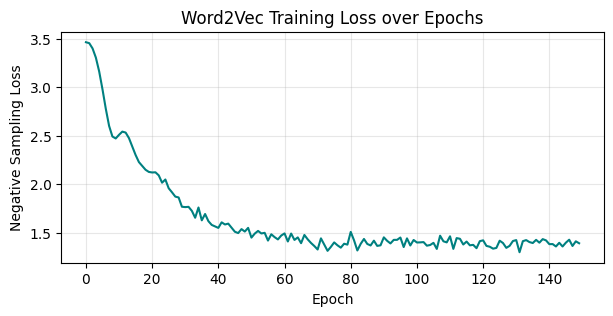

In [7]:
# Hyperparameters
EMBED_DIM = 16
K_NEGATIVES = 4
LEARNING_RATE = 0.05
EPOCHS = 150

model = SkipGramNegSampling(vocab_size=V, embed_dim=EMBED_DIM)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Unigram distribution for negative sampling (Mikolov used frequency^0.75)
counts = np.array([word_counts[idx2word[i]] for i in range(V)], dtype=np.float32)
probs = counts ** 0.75
probs /= probs.sum()

target_tensor = torch.tensor([p[0] for p in training_pairs], dtype=torch.long)
pos_context_tensor = torch.tensor([p[1] for p in training_pairs], dtype=torch.long)

losses = []
for epoch in range(EPOCHS):
    # Sample k negatives for each pair
    neg_samples = np.random.choice(V, size=(len(training_pairs), K_NEGATIVES), p=probs)
    neg_tensor = torch.tensor(neg_samples, dtype=torch.long)
    
    optimizer.zero_grad()
    loss = model(target_tensor, pos_context_tensor, neg_tensor)
    loss.backward()
    optimizer.step()
    
    losses.append(loss.item())
    if (epoch + 1) % 30 == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(losses, color='teal')
plt.title("Word2Vec Training Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Negative Sampling Loss")
plt.grid(True, alpha=0.3)
plt.show()


---
## 6. Inspecting Learned Word Embeddings

Now let's extract the learned vectors and inspect semantic similarities using Cosine Similarity!


In [8]:
embeddings = model.get_embeddings()

def get_most_similar(word, top_n=4):
    if word not in word2idx:
        return f"'{word}' not in vocabulary"
    idx = word2idx[word]
    vec = embeddings[idx]
    
    # Compute cosine similarity with all words
    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
    normed_embeddings = embeddings / (norms + 1e-10)
    normed_vec = vec / (np.linalg.norm(vec) + 1e-10)
    
    sims = np.dot(normed_embeddings, normed_vec)
    sorted_indices = np.argsort(sims)[::-1]
    
    results = []
    for i in sorted_indices[1:top_n+1]: # skip the word itself
        results.append((idx2word[i], float(sims[i])))
    return results

print("Most similar to 'king':", get_most_similar('king'))
print("Most similar to 'apples':", get_most_similar('apples'))
print("Most similar to 'dogs':", get_most_similar('dogs'))


Most similar to 'king': [('queen', 0.802148699760437), ('garden', 0.7476407885551453), ('ruled', 0.635461151599884), ('alongside', 0.6005293130874634)]
Most similar to 'apples': [('delicious', 0.7229276895523071), ('farmer', 0.7200679779052734), ('are', 0.71031653881073), ('fruits', 0.7021591663360596)]
Most similar to 'dogs': [('are', 0.785216212272644), ('popular', 0.6614450216293335), ('sweet', 0.6505268216133118), ('oranges', 0.6316324472427368)]


---
## 7. The Fatal Bottleneck: Polysemy

Word2Vec and all static embedding models (GloVe, FastText) suffer from a critical limitation:
**Each word is assigned exactly one fixed vector in the lookup table.**

Consider the word **"bank"**:
* Sentence A: *"He deposited money into his **bank** account."* (Financial institution)
* Sentence B: *"They sat on the muddy river **bank** fishing."* (Geographical riverbank)

In Word2Vec:
$$\mathbf{v}_{\text{bank}} = \text{lookup}(\text{"bank"})$$

The vector for `"bank"` is forced to be a conflation (a weighted average) of all its meanings!

```
      [Financial Bank]
             │
             ▼
    [Combined Vector: "bank"] ◄── Static Compromise
             ▲
             │
       [River Bank]
```

To solve this, NLP needed **Contextualized Embeddings**, where a word's vector changes dynamically depending on the surrounding sentence.

---
## Summary of Notebook 02
1. **One-Hot Encoding** produces orthogonal vectors with zero semantic understanding.
2. **Distributional Hypothesis**: Words that occur in similar contexts share similar meanings.
3. **Word2Vec (Skip-Gram)** frames word embedding as predicting context words from a center target word.
4. **Negative Sampling** bypasses the full-vocabulary softmax bottleneck, turning training into efficient binary classification.
5. **Static Limitation**: Word2Vec cannot handle **polysemy** or sentence-level semantics.

In **Notebook 03**, we will see how **Transformers and BERT** revolutionized embeddings by generating **Dynamic, Contextual Representations**!
